# Домашно 1 #
## Матей Захариев 9MI0200067 ##

In [163]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Не ми бачкаше output-а на jupiter notebook. Това го оправя.
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

### Задача 1. ###
Зареждане и първоначален преглед (1 т.)
Заредете данните в DataFrame.
Изведете:
първите 5 реда;
размерността на таблицата;
типовете на променливите.
Проверете за липсващи стойности.
Въпроси:

Колко наблюдения съдържа наборът?
Кои променливи са числови?

In [164]:
FILEPATH = "Brain_Data.xlsx"

df = pd.read_excel(FILEPATH)
df.head(5)
df.shape
df.dtypes
df[df.isna().any(axis=1)]


,Gender,FSIQ,VIQ,PIQ,Weight,Height,MRI_Count
0,Female,133,132,124,118.0,64.5,816932
1,Male,140,150,124,NaN,72.5,1001121
2,Male,139,123,150,143.0,73.3,1038437
3,Male,133,129,128,172.0,68.8,965353
4,Female,137,132,134,147.0,65.0,951545


(40, 7)

Gender           str
FSIQ           int64
VIQ            int64
PIQ            int64
Weight       float64
Height       float64
MRI_Count      int64
dtype: object

,Gender,FSIQ,VIQ,PIQ,Weight,Height,MRI_Count
1,Male,140,150,124,NaN,72.5,1001121
20,Male,83,83,86,NaN,NaN,892420


Както виждаме, имаме 40 наблюдения и всички променливи без gender са числови.

In [165]:
numerical = df.keys()
numerical = numerical.delete(0)
numerical

Index(['FSIQ', 'VIQ', 'PIQ', 'Weight', 'Height', 'MRI_Count'], dtype='str')

### Задача 2. ###
Изчислете за всяка числова променлива:

брой наблюдения;
средна стойност;
медиана;
стандартно отклонение;
минимум;
максимум.
Представете резултатите в таблица.

Въпроси:

Коя променлива има най-голяма вариабилност?
Съществуват ли екстремни стойности?

In [166]:
# Правим функция за бъдещо ползване.
def get_stats(df):
    return pd.DataFrame({  
        "count":df[numerical].notna().sum(),
        "mean":df[numerical].mean(),
        "median":df[numerical].median(),
        "std":df[numerical].std(),
        "min":df[numerical].min(),
        "max":df[numerical].max()
    })

#Използваме горепосочената функция
stats = get_stats(df)
stats

,count,mean,median,std,min,max
FSIQ,40,113.450000,116.5,24.082071,77.0,144.0
VIQ,40,112.350000,113.0,23.616107,71.0,150.0
PIQ,40,111.025000,115.0,22.471050,72.0,150.0
Weight,38,151.052632,146.5,23.478509,106.0,192.0
Height,39,68.525641,68.0,3.994649,62.0,77.0
MRI_Count,40,908755.000000,905399.0,72282.048931,790619.0,1079549.0


Вижда се, че MRI_Count има най-голямо стандартно отклонение, но нека разгледаме тези стойности спрямо средното.

In [167]:
stats["std"]/stats["mean"]

FSIQ         0.212270
VIQ          0.210201
PIQ          0.202396
Weight       0.155433
Height       0.058294
MRI_Count    0.079540
dtype: float64

Съответно забелязваме, че MRI_Count в същност има сравнително по малка относителна варияция спрямо други, като FSIQ и VIQ. Нека построим квартили за да търсим отличаващи се елементи.

In [168]:
stats["Q1"] = df[numerical].quantile(0.25)
stats["Q3"] = df[numerical].quantile(0.75)
stats["IQR"] = stats["Q3"]-stats["Q1"]

# За всяка колона създаваме маска дали са под Q1-1.5*IQR или над Q3+1.5*IQR и сумираме
stats["outlier_count"] = df[numerical].apply(
    lambda x: x[
        (x<(stats.loc[x.name,"Q1"]-1.5*stats.loc[x.name,"IQR"])) |
        (x>(stats.loc[x.name,"Q3"]+1.5*stats.loc[x.name,"IQR"]))
    ].sum()
)
stats["outlier_count"]

FSIQ         0.0
VIQ          0.0
PIQ          0.0
Weight       0.0
Height       0.0
MRI_Count    0.0
Name: outlier_count, dtype: float64

Виждаме, че нямаме екстремни данни.

### Задача 3. ###
Изчислете по пол:

среден FSIQ;
среден VIQ;
среден PIQ;
среден MRI_Count.
Получената таблица да бъде сортирана по средния FSIQ.

Допълнително:

Изчислете и броя наблюдения във всяка група.

In [169]:
df_male = df[df["Gender"]=="Male"]
df_female = df[df["Gender"]=="Female"]

# Използваме по-нагоре-посочената функция отново :)
stats_male = get_stats(df_male)
stats_female = get_stats(df_female)

stats_mean_by_gender = pd.DataFrame({
    "Male":stats_male["mean"],
    "Female":stats_female["mean"]
}).T
stats_mean_by_gender["Count"]=[df_male.shape[0],df_female.shape[0]]
stats_mean_by_gender.sort_values("FSIQ")


,FSIQ,VIQ,PIQ,Weight,Height,MRI_Count,Count
Female,111.9,109.45,110.45,137.200000,65.765000,862654.6,20
Male,115.0,115.25,111.60,166.444444,71.431579,954855.4,20


### Задача 4. ###
Създайте следните графики:

4.1 Хистограми
За:

FSIQ
VIQ
PIQ

4.2 Boxplots
За:

Weight
Height
MRI_Count
4.3 Scatter plot

Нанесете:

MRI_Count срещу FSIQ.
Добавете линия на линейна регресия.

Въпроси:

Има ли наблюдения с необичайно големи стойности?
Вижда ли се линейна зависимост между размера на мозъка и IQ?

array([[<Axes: title={'center': 'FSIQ'}>,
        <Axes: title={'center': 'VIQ'}>],
       [<Axes: title={'center': 'PIQ'}>, <Axes: >]], dtype=object)

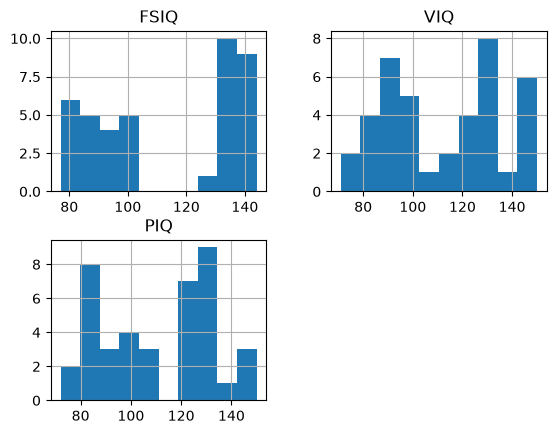

<Axes: >

<Axes: >

<Axes: >

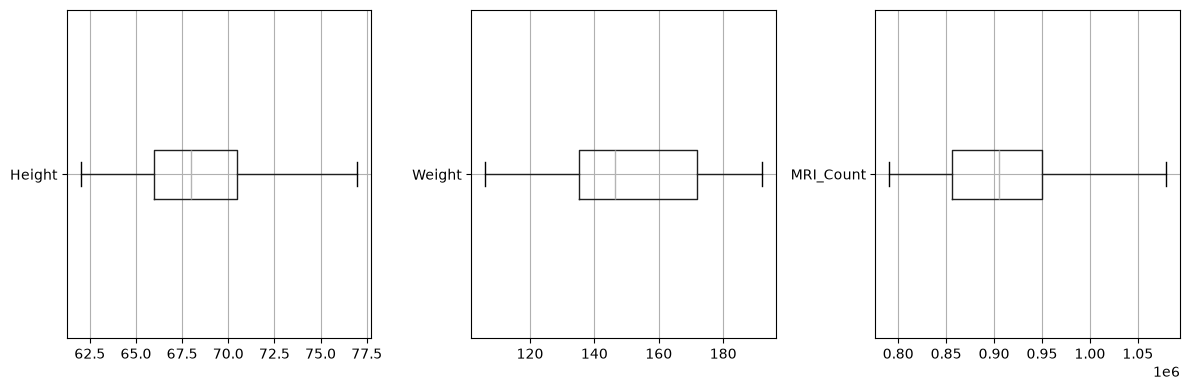

<Axes: xlabel='MRI_Count', ylabel='FSIQ'>

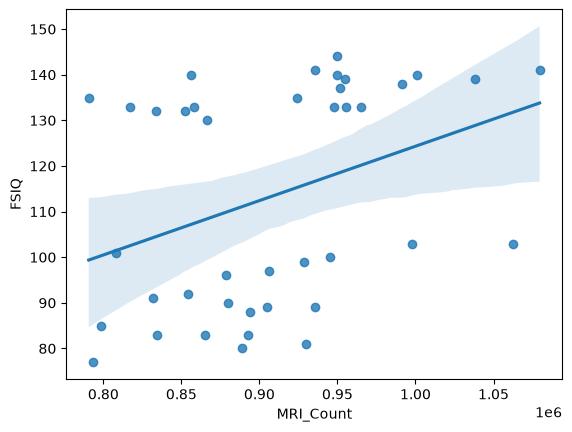

In [170]:
df[["FSIQ", "VIQ", "PIQ"]].hist()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, col in zip(axes, ["Height", "Weight", "MRI_Count"]):
    df.boxplot(column=col, ax=ax, vert=False)

plt.tight_layout()
plt.show()


sns.regplot(x=df["MRI_Count"], y=df["FSIQ"])
plt.show()

Личи голямо разделение на данните за FSIQ, което може да се съпостави и изследва още. Както забелязахме и миналия път, екстремни стойности няма. Вижда се слаба линейна зависимост между размера на мозъка и IQ, но е препоръчително да се съберат още данни за да се покрие дупката в  FSIQ

### Задача 5. ###
Оценете корелацията визуално на следните параметри :

FSIQ
VIQ
PIQ
Weight
Height
MRI_Count
Визуализирайте я чрез heatmap.

Въпроси:

Коя двойка променливи има най-силна положителна корелация?
Съществува ли силна връзка между MRI_Count и интелигентноста?

<Figure size 800x800 with 0 Axes>

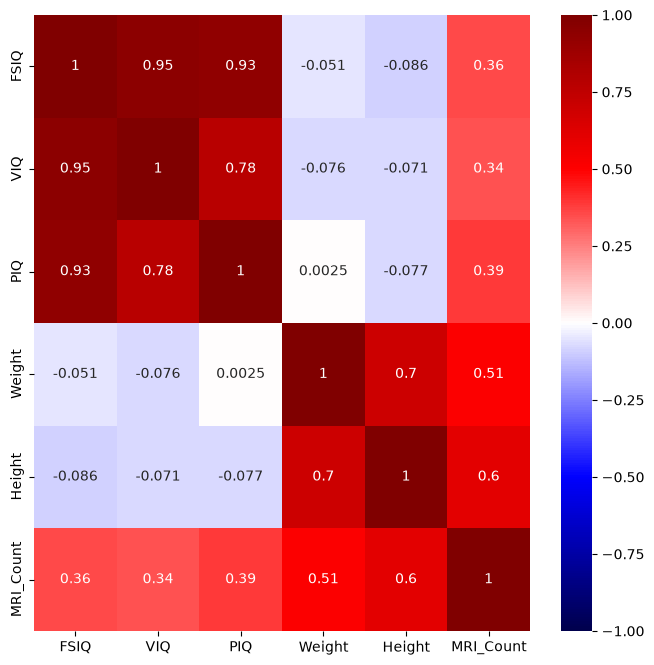

In [171]:
corr_matrix = df[numerical].corr()
plt.figure(figsize=(8,8))
ax = sns.heatmap(corr_matrix,annot=True,vmin=-1,vmax=1,cmap="seismic")
plt.show()

Виждаме сравнителна положителна корелация между трите IQ статистики(Най-силна между FSIQ и VIQ), както и между височина, тежест и размер на мозъка. Освен това се вижда слаба положителна корелация между размер на мозъка и IQ статистика. Останалите са сравнително некорелирани (но като нисък човек ще си затворя очите и ще си представя че стойностите за височина - iq имат една по-малко нули след точката) 